# Alerta temprana de bajo desempeño en Saber 11 — Cali
## Análisis Exploratorio de Datos (EDA) · Primer entregable 

El notebook sigue las 7 etapas de EDA vistas en clase:
**Datos crudos → Análisis descriptivo → Ajuste de tipos → Datos faltantes → Atípicos → Correlación → Conclusiones**,
y cierra con una prueba de viabilidad del modelo (línea base vs. modelos multivariados).

**Fuente:** ICFES — *Resultados únicos Saber 11*, portal de Datos Abiertos de Colombia
(datos.gov.co, id `kgxf-xxbe`). Filtro: colegios ubicados en Cali, periodos 2019-1, 2019-2, 2022-1 y 2022-2.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import chi2_contingency

DATA = Path("data/raw/saber11_cali_2019_2022.csv")
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)

BLUE, ORANGE, AQUA, GRAY, INK, INK2 = "#4a3aa7", "#d08c00", "#1baf7a", "#a3a29c", "#0b0b0b", "#52514e"  # violeta, ámbar, aqua
SEQ = ["#e4e0f5", "#c7bfeb", "#a79ade", "#8676cf", "#6655bd", "#4a3aa7", "#34287a"]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Datos crudos

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
print("Registros:", f"{len(raw):,}", "| Variables:", raw.shape[1])
raw["periodo"] = raw["periodo"].astype(str)
raw["periodo"].value_counts().sort_index()

Registros: 80,350 | Variables: 51


periodo
20191     5182
20194    36012
20221     5448
20224    33708
Name: count, dtype: int64

In [3]:
raw.head(3).T

,0,1,2
periodo,20191,20191,20191
estu_tipodocumento,CC,TI,TI
estu_consecutivo,SB11201910006872,SB11201910004673,SB11201910001971
cole_area_ubicacion,URBANO,URBANO,URBANO
cole_bilingue,N,S,N
cole_calendario,B,B,B
cole_caracter,TÉCNICO,ACADÉMICO,ACADÉMICO
cole_cod_dane_establecimiento,376001000900,376001043617,376001006983
cole_cod_dane_sede,376001000900,376001043617,376001006983
cole_cod_depto_ubicacion,76,76,76


### 1.1 Hallazgo de calidad: filas duplicadas en la fuente oficial
El portal publica filas **idénticas** (mismo `estu_consecutivo` y mismas 51 columnas).
Se verificó contra la API: para 2022-2 hay 33.708 filas pero solo 16.854 estudiantes distintos.

In [4]:
dup = raw.duplicated()
print(f"Filas duplicadas exactas: {dup.sum():,} ({dup.mean():.1%})")
print(raw.assign(dup=dup).groupby("periodo")["dup"].agg(["sum", "size"]))
df = raw.drop_duplicates().copy()
assert df["estu_consecutivo"].is_unique
print("Tras eliminar duplicados:", f"{len(df):,}")

Filas duplicadas exactas: 36,221 (45.1%)
           sum   size
periodo              
20191       21   5182
20194    19346  36012
20221        0   5448
20224    16854  33708
Tras eliminar duplicados: 44,129


### 1.2 Filtros de calidad
* Se excluyen resultados no publicados por el ICFES (en investigación de identidad/validez).
* Se excluyen puntajes globales iguales a 0 (examen no presentado / anulado).

In [5]:
paso = {"Filas publicadas en el portal": len(raw), "Sin duplicados": len(df)}
df = df[df["estu_estadoinvestigacion"].eq("PUBLICAR")].copy()
paso["Resultado publicado (no en investigación)"] = len(df)
df = df[df["punt_global"] > 0].copy()
paso["Registros válidos para el EDA"] = len(df)

df["anio"] = df["periodo"].str[:4]
anios_disponibles = sorted(df["anio"].dropna().unique())
print("Años encontrados en el archivo:", anios_disponibles)
print("\nRegistros por año:")
print(df["anio"].value_counts().sort_index())

esperados = {"2019", "2020", "2021", "2022"}
faltantes = sorted(esperados - set(anios_disponibles))
if faltantes:
    print("\n⚠️ El archivo cargado NO contiene registros de:", ", ".join(faltantes))
else:
    print("\n✓ El archivo contiene 2019, 2020, 2021 y 2022.")

pd.Series(paso, name="registros").to_frame()


Años encontrados en el archivo: ['2019', '2022']

Registros por año:
anio
2019    21788
2022    22289
Name: count, dtype: int64

⚠️ El archivo cargado NO contiene registros de: 2020, 2021


,registros
Filas publicadas en el portal,80350
Sin duplicados,44129
Resultado publicado (no en investigación),44078
Registros válidos para el EDA,44077


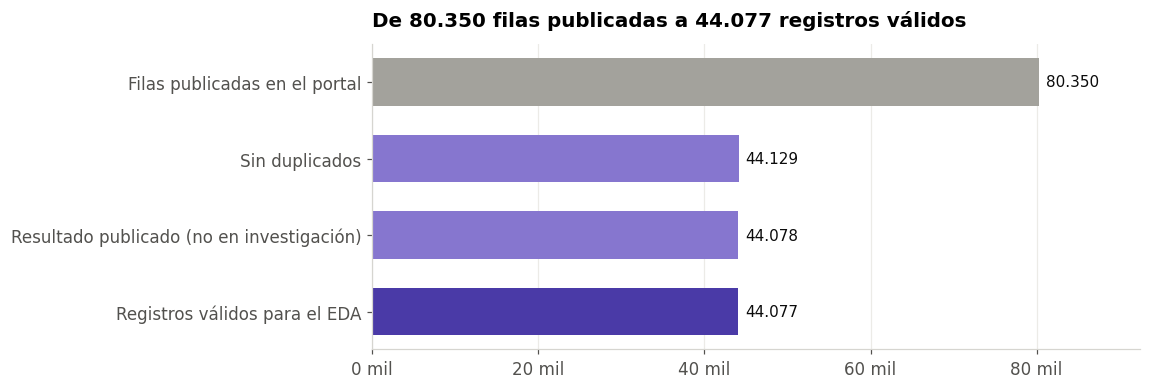

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels, vals = list(paso.keys())[::-1], list(paso.values())[::-1]
bars = ax.barh(labels, vals, color=[BLUE] + [SEQ[3]] * (len(vals)-2) + [GRAY], height=0.62)
for b, v in zip(bars, vals):
    ax.text(v + max(vals)*0.01, b.get_y() + b.get_height()/2, f"{v:,}".replace(",", "."), va="center", color=INK, fontsize=10)
ax.set_title(f"De {len(raw):,} filas publicadas a {len(df):,} registros válidos".replace(",", "."))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f} mil"))
ax.set_xlim(0, max(vals) * 1.15); ax.grid(axis="y", visible=False)
save(fig, "f01_embudo_limpieza")


## 2. Variable objetivo y análisis descriptivo
**Bajo desempeño = puntaje global < 250.** La escala global va de 0 a 500 y 250 es su punto medio
(cada prueba se reporta de 0 a 100 con media de referencia 50). Esto da clases casi balanceadas.

In [7]:
df["bajo"] = (df["punt_global"] < 250).astype(int)
print(df["bajo"].value_counts().rename({0: "≥ 250", 1: "< 250 (bajo)"}))
print(f"Tasa de bajo desempeño general: {df['bajo'].mean():.1%}")
print("\nTasa por año:")
print(df.groupby("anio")["bajo"].agg(["count", "mean"]).rename(columns={"count":"n", "mean":"tasa_bajo"}).round(3))
df["punt_global"].describe().round(1)


bajo
≥ 250           24682
< 250 (bajo)    19395
Name: count, dtype: int64
Tasa de bajo desempeño general: 44.0%

Tasa por año:
          n  tasa_bajo
anio                  
2019  21788      0.447
2022  22289      0.434


count    44077.0
mean       260.0
std         53.3
min         87.0
25%        220.0
50%        258.0
75%        298.0
max        468.0
Name: punt_global, dtype: float64

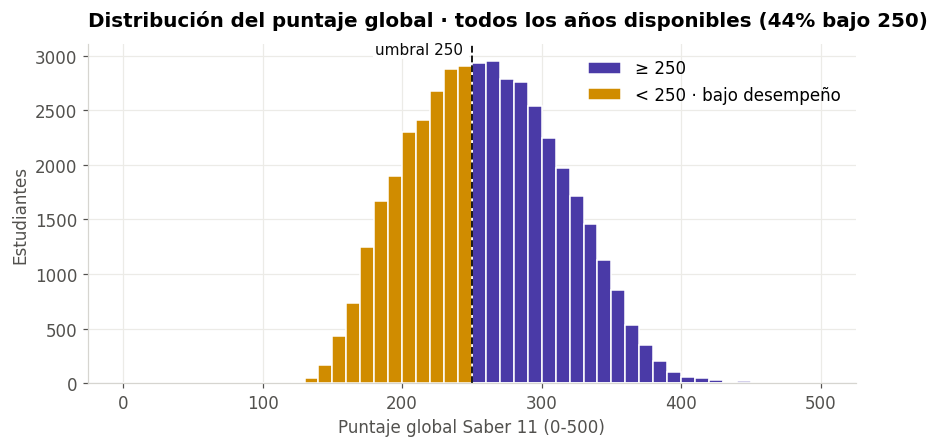

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 501, 10)
ax.hist(df.loc[df.bajo == 0, "punt_global"], bins=bins, color=BLUE, label="≥ 250", edgecolor="white", linewidth=1)
ax.hist(df.loc[df.bajo == 1, "punt_global"], bins=bins, color=ORANGE, label="< 250 · bajo desempeño", edgecolor="white", linewidth=1)
ax.axvline(250, color=INK, lw=1.2, ls="--")
ax.text(247, ax.get_ylim()[1] * 0.97, "umbral 250 ", color=INK, fontsize=10, ha="right", bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_title(f"Distribución del puntaje global · todos los años disponibles ({df.bajo.mean():.0%} bajo 250)")
ax.set_xlabel("Puntaje global Saber 11 (0-500)"); ax.set_ylabel("Estudiantes"); ax.legend()
save(fig, "f02_distribucion_puntaje")


## 3. Ajuste de tipos y construcción de variables
Las variables del hogar vienen como texto por rangos. Se convierten a numéricas/ordinales y se
construyen variables derivadas con sentido pedagógico.

In [9]:
def edad_examen(d):
    nac = pd.to_datetime(d["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
    ref = pd.to_datetime(d["periodo"].str[:4] + np.where(d["periodo"].str[-1] == "1", "-03-15", "-08-15"))
    e = (ref - nac).dt.days / 365.25
    return e.where(e.between(12, 80))

PERSONAS = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5}
CUARTOS = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}
EDU = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
       "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
       "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
EDU_CORTA = ["Ninguno", "Primaria inc.", "Primaria", "Secundaria inc.", "Secundaria", "Técnica inc.", "Técnica",
             "Profesional inc.", "Profesional", "Posgrado"]
BIENES = ["fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora"]

def construir(d):
    d = d.copy()
    d["edad"] = edad_examen(d)
    d["extraedad"] = (d["edad"] >= 19).astype(float).where(d["edad"].notna())
    d["personas"] = d["fami_personashogar"].map(PERSONAS)
    d["cuartos"] = d["fami_cuartoshogar"].map(CUARTOS)
    d["hacinamiento"] = d["personas"] / d["cuartos"]
    d["estrato"] = d["fami_estratovivienda"].str.extract(r"(\d)").astype(float)
    d["edu_madre"] = d["fami_educacionmadre"].map(EDU)
    d["edu_padre"] = d["fami_educacionpadre"].map(EDU)
    d["edu_max_padres"] = d[["edu_madre", "edu_padre"]].max(axis=1)
    b = d[BIENES].replace({"Si": 1, "No": 0})
    d["indice_bienes"] = b.sum(axis=1, min_count=1)
    d["reside_fuera_cali"] = (d["estu_mcpio_reside"] != "CALI").astype(int)
    d["mujer"] = (d["estu_genero"] == "F").astype(int)
    return d

df = construir(df)
df[["edad", "personas", "cuartos", "hacinamiento", "estrato", "edu_madre", "indice_bienes"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
edad,44029.0,17.71,2.90,12.01,16.72,17.23,17.99,77.59
personas,41936.0,4.16,1.65,1.50,3.50,3.50,5.50,9.50
cuartos,41846.0,2.90,1.02,1.00,2.00,3.00,3.00,6.00
hacinamiento,41761.0,1.53,0.69,0.25,1.17,1.38,1.75,9.50
estrato,40169.0,2.54,1.21,1.00,2.00,2.00,3.00,6.00
edu_madre,39682.0,4.59,2.28,0.00,3.00,4.00,6.00,9.00
indice_bienes,42939.0,2.68,1.16,0.00,2.00,3.00,4.00,4.00


### Tablero de estadísticas iniciales

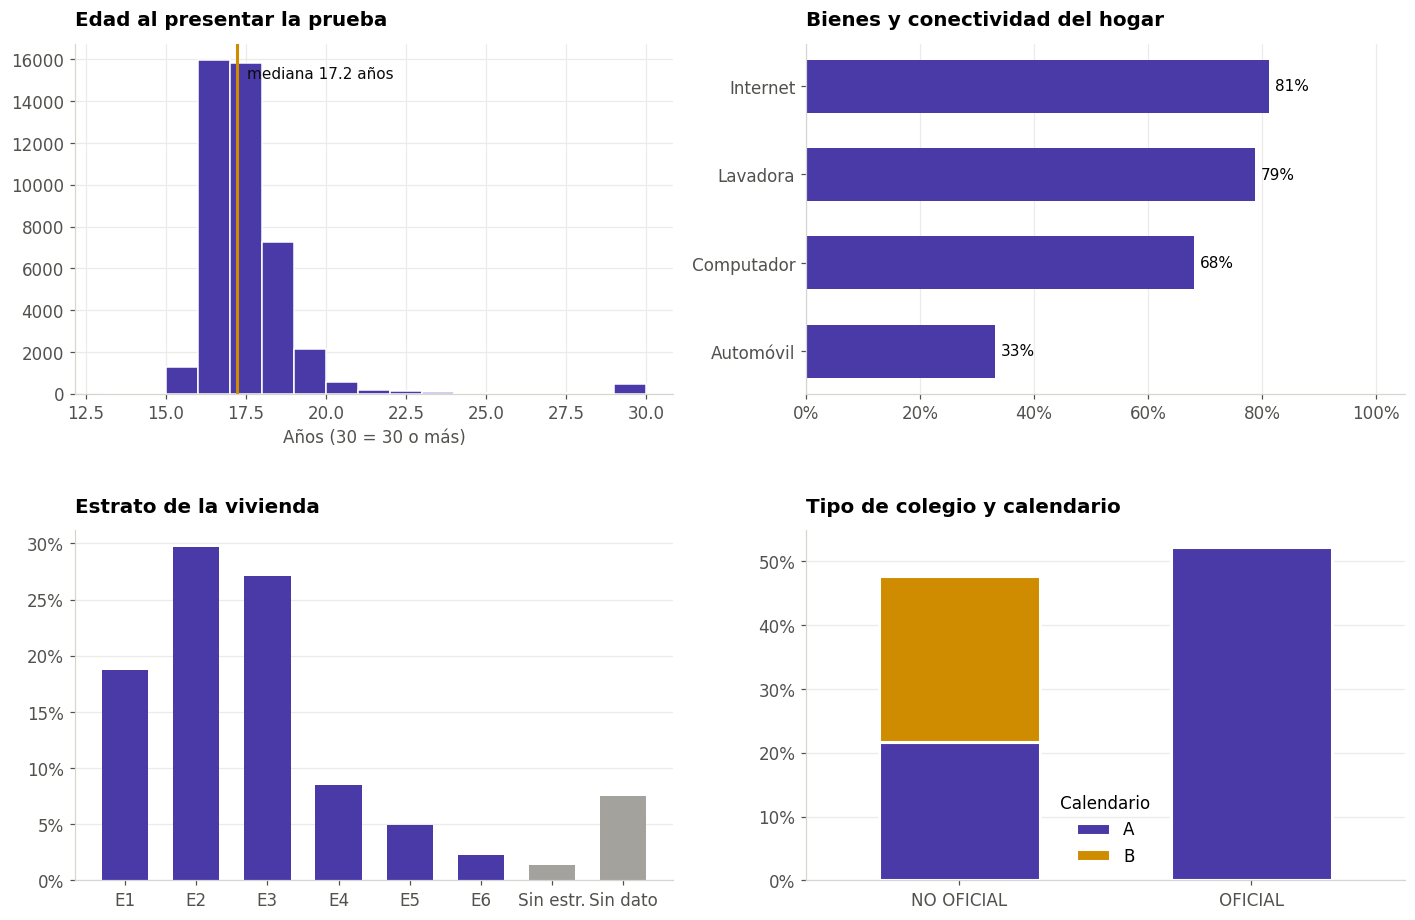

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))
ax = axs[0, 0]
ax.hist(df["edad"].clip(upper=30), bins=np.arange(13, 31, 1), color=BLUE, edgecolor="white")
ax.axvline(df["edad"].median(), color=ORANGE, lw=2); ax.text(df["edad"].median() + .3, ax.get_ylim()[1] * .9, f"mediana {df['edad'].median():.1f} años", color=INK, fontsize=10)
ax.set_title("Edad al presentar la prueba"); ax.set_xlabel("Años (30 = 30 o más)")

ax = axs[0, 1]
share = pd.Series({"Lavadora": df.fami_tienelavadora.eq("Si").mean(), "Internet": df.fami_tieneinternet.eq("Si").mean(),
                   "Computador": df.fami_tienecomputador.eq("Si").mean(), "Automóvil": df.fami_tieneautomovil.eq("Si").mean()}).sort_values()
ax.barh(share.index, share.values, color=BLUE, height=.6)
for i, v in enumerate(share.values): ax.text(v + .01, i, f"{v:.0%}", va="center", fontsize=10)
ax.set_xlim(0, 1.05); ax.xaxis.set_major_formatter(pct); ax.set_title("Bienes y conectividad del hogar"); ax.grid(axis="y", visible=False)

ax = axs[1, 0]
est = df["fami_estratovivienda"].fillna("Sin dato").value_counts()
orden = ["Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6", "Sin Estrato", "Sin dato"]
est = est.reindex(orden).fillna(0)
ax.bar(["E1", "E2", "E3", "E4", "E5", "E6", "Sin estr.", "Sin dato"], est.values / len(df), color=[BLUE] * 6 + [GRAY] * 2, width=.65)
ax.yaxis.set_major_formatter(pct); ax.set_title("Estrato de la vivienda"); ax.grid(axis="x", visible=False)

ax = axs[1, 1]
nat = df.groupby(["cole_naturaleza", "cole_calendario"]).size().unstack(fill_value=0)
nat = nat.div(len(df))
nat.plot(kind="bar", stacked=True, ax=ax, color=[BLUE, ORANGE], width=.55, edgecolor="white", linewidth=2, rot=0)
ax.yaxis.set_major_formatter(pct); ax.set_title("Tipo de colegio y calendario"); ax.set_xlabel(""); ax.legend(title="Calendario"); ax.grid(axis="x", visible=False)
fig.tight_layout(h_pad=3)
save(fig, "f03_tablero_inicial")

In [11]:
print(f"Colegios: {df.cole_cod_dane_establecimiento.nunique()} | Sedes: {df.cole_cod_dane_sede.nunique()}")
print(f"Oficiales: {df.cole_naturaleza.eq('OFICIAL').mean():.1%} | Mujeres: {df.mujer.mean():.1%} | Rural: {df.cole_area_ubicacion.eq('RURAL').mean():.1%}")
print(f"Calendario B: {df.cole_calendario.eq('B').mean():.1%} | Extraedad (≥19): {df.extraedad.mean():.1%} | Venezolanos: {df.estu_nacionalidad.eq('VENEZUELA').sum()}")

Colegios: 404 | Sedes: 450
Oficiales: 52.3% | Mujeres: 54.8% | Rural: 4.1%
Calendario B: 26.0% | Extraedad (≥19): 8.4% | Venezolanos: 342


## 4. Datos faltantes
¿Los faltantes son aleatorios? Si quien no reporta su estrato tiene un desempeño distinto,
el faltante **es información** y no se debe eliminar ni imputar a ciegas.

In [12]:
cols_na = ["cole_bilingue", "fami_estratovivienda", "fami_tieneinternet", "fami_educacionpadre", "fami_educacionmadre",
           "fami_tieneautomovil", "fami_tienecomputador", "fami_tienelavadora", "fami_cuartoshogar", "fami_personashogar", "cole_caracter"]
na = pd.DataFrame({
    "% faltante": df[cols_na].isna().mean(),
    "% bajo si falta": [df.loc[df[c].isna(), "bajo"].mean() for c in cols_na],
    "% bajo si no falta": [df.loc[df[c].notna(), "bajo"].mean() for c in cols_na],
}).sort_values("% faltante")
print(f"Estudiantes con al menos un dato familiar faltante: {df[cols_na[1:10]].isna().any(axis=1).mean():.1%}")
na.style.format("{:.1%}")

Estudiantes con al menos un dato familiar faltante: 11.3%


,% faltante,% bajo si falta,% bajo si no falta
cole_caracter,4.5%,50.1%,43.7%
fami_personashogar,4.9%,51.8%,43.6%
fami_tienecomputador,5.0%,52.6%,43.5%
fami_tienelavadora,5.0%,52.6%,43.6%
fami_cuartoshogar,5.1%,51.5%,43.6%
fami_tieneautomovil,5.3%,53.8%,43.5%
fami_educacionmadre,6.9%,61.4%,42.7%
fami_educacionpadre,6.9%,61.9%,42.7%
fami_tieneinternet,7.0%,61.6%,42.7%
fami_estratovivienda,7.5%,61.5%,42.6%


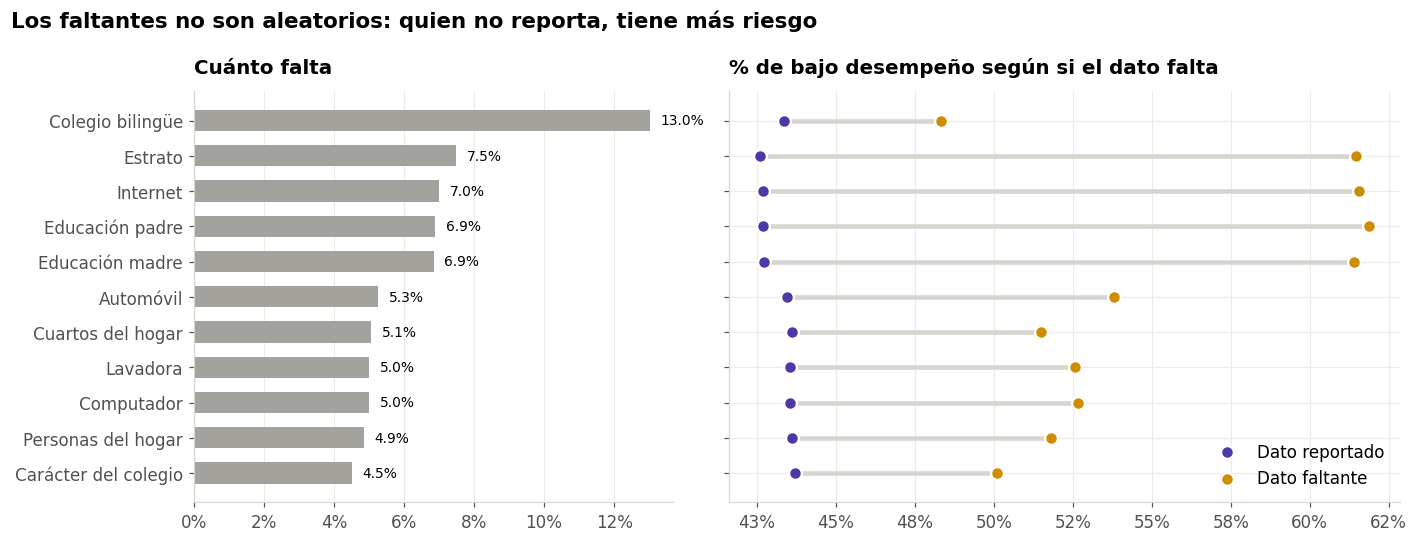

In [13]:
nombres = {"cole_bilingue": "Colegio bilingüe", "fami_estratovivienda": "Estrato", "fami_tieneinternet": "Internet",
           "fami_educacionpadre": "Educación padre", "fami_educacionmadre": "Educación madre", "fami_tieneautomovil": "Automóvil",
           "fami_tienecomputador": "Computador", "fami_tienelavadora": "Lavadora", "fami_cuartoshogar": "Cuartos del hogar",
           "fami_personashogar": "Personas del hogar", "cole_caracter": "Carácter del colegio"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
y = np.arange(len(na)); lab = [nombres[c] for c in na.index]
a1.barh(y, na["% faltante"], color=GRAY, height=.6); a1.set_yticks(y, lab); a1.xaxis.set_major_formatter(pct)
for i, v in enumerate(na["% faltante"]): a1.text(v + .003, i, f"{v:.1%}", va="center", fontsize=9)
a1.set_title("Cuánto falta"); a1.grid(axis="y", visible=False)
a2.hlines(y, na["% bajo si no falta"], na["% bajo si falta"], color="#d6d5d0", lw=3)
a2.scatter(na["% bajo si no falta"], y, color=BLUE, s=70, zorder=3, label="Dato reportado", edgecolor="white", linewidth=1.5)
a2.scatter(na["% bajo si falta"], y, color=ORANGE, s=70, zorder=3, label="Dato faltante", edgecolor="white", linewidth=1.5)
a2.xaxis.set_major_formatter(pct); a2.set_title("% de bajo desempeño según si el dato falta"); a2.legend(loc="lower right")
fig.suptitle("Los faltantes no son aleatorios: quien no reporta, tiene más riesgo", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "f04_faltantes")

**Decisión:** en variables categóricas el faltante se codifica como categoría propia `"Sin información"`;
en numéricas derivadas se imputa con la mediana **dentro del conjunto de entrenamiento** y se agrega un indicador de faltante.
`cole_bilingue` falta sobre todo en colegios oficiales (se imputa "N" tras verificarlo).

In [14]:
print(pd.crosstab(df["cole_naturaleza"], df["cole_bilingue"].isna(), normalize="index").round(3))

cole_bilingue    False  True 
cole_naturaleza              
NO OFICIAL       0.879  0.121
OFICIAL          0.862  0.138


## 5. Valores atípicos
Regla IQR vista en clase: atípico si está fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR].

In [15]:
num = {"edad": "Edad (años)", "personas": "Personas en el hogar", "hacinamiento": "Personas por cuarto", "punt_global": "Puntaje global"}
res = []
for c in num:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    res.append({"variable": num[c], "Q1": q1, "Q3": q3, "IQR": iqr, "lím. inf": lo, "lím. sup": hi,
                "n atípicos": int(((s < lo) | (s > hi)).sum()), "% atípicos": ((s < lo) | (s > hi)).mean()})
out = pd.DataFrame(res).set_index("variable"); out.style.format({"% atípicos": "{:.1%}", "Q1": "{:.1f}", "Q3": "{:.1f}", "IQR": "{:.1f}", "lím. inf": "{:.1f}", "lím. sup": "{:.1f}"})

,Q1,Q3,IQR,lím. inf,lím. sup,n atípicos,% atípicos
variable,,,,,,,
Edad (años),16.7,18.0,1.3,14.8,19.9,1657,3.8%
Personas en el hogar,3.5,5.5,2.0,0.5,8.5,883,2.1%
Personas por cuarto,1.2,1.8,0.6,0.3,2.6,3079,7.4%
Puntaje global,220.0,298.0,78.0,103.0,415.0,76,0.2%


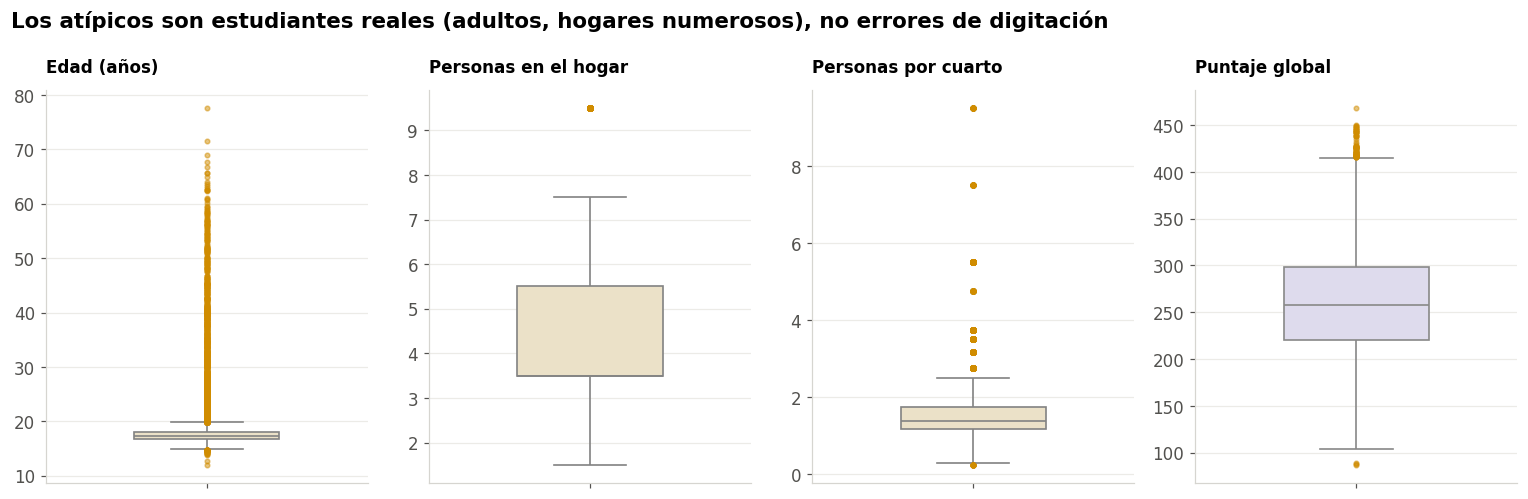

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(14, 4.6))
for ax, c in zip(axs, num):
    sns.boxplot(y=df[c], ax=ax, color="#f1e3c2" if c != "punt_global" else "#dcd8f0", width=.45, linewidth=1.1,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor=ORANGE, alpha=.5))
    ax.set_title(num[c], fontsize=11); ax.set_ylabel(""); ax.grid(axis="x", visible=False)
fig.suptitle("Los atípicos son estudiantes reales (adultos, hogares numerosos), no errores de digitación",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "f05_atipicos")

In [17]:
adultos = df[df.edad >= 25]
print(f"Estudiantes de 25+ años: {len(adultos)} — jornada:")
print(adultos["cole_jornada"].value_counts(normalize=True).round(3).head())
print(f"% bajo desempeño en 25+: {adultos.bajo.mean():.1%} vs {df.loc[df.edad < 25, 'bajo'].mean():.1%} en < 25")

Estudiantes de 25+ años: 604 — jornada:
cole_jornada
NOCHE       0.593
SABATINA    0.348
MAÑANA      0.041
TARDE       0.017
COMPLETA    0.002
Name: proportion, dtype: float64
% bajo desempeño en 25+: 88.9% vs 43.4% en < 25


**Decisión:** la regla IQR marca como "atípicos" a todos los mayores de ~19,5 años porque el IQR de la edad es
de apenas un año (casi todos tienen 16-18). Son adultos de jornadas nocturnas y sabatinas: **un grupo real
y de alto riesgo**, no ruido. Se conservan y se representan con la variable `extraedad`.
Solo se eliminaron los puntajes globales iguales a 0 (paso 1.2).

## 6. Relaciones con la variable objetivo

In [18]:
def tasa(d, col, orden=None, minimo=30):
    t = d.groupby(col, dropna=False)["bajo"].agg(tasa="mean", n="size")
    t = t[t.n >= minimo]
    return t.reindex(orden).dropna() if orden else t.sort_values("tasa")

### 6.1 Estrato y bajo desempeño en todos los años disponibles


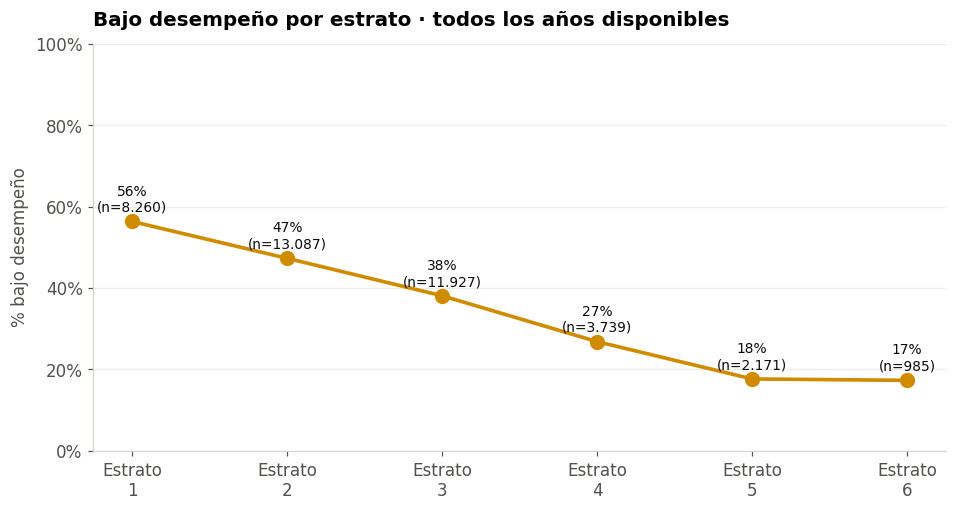

,tasa,n
fami_estratovivienda,,
Estrato 1,0.563,8260
Estrato 2,0.473,13087
Estrato 3,0.381,11927
Estrato 4,0.268,3739
Estrato 5,0.176,2171
Estrato 6,0.173,985


In [19]:
orden_e = ["Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6"]
est = tasa(df, "fami_estratovivienda", orden_e)
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(est))
ax.plot(x, est.tasa, marker="o", ms=9, lw=2.4, color=ORANGE)
for i, (v, n) in enumerate(zip(est.tasa, est.n)):
    ax.text(i, v + .025, f"{v:.0%}\n(n={int(n):,})".replace(",", "."), ha="center", fontsize=9, color=INK)
ax.set_xticks(x, [o.replace("Estrato ", "Estrato\n") for o in est.index])
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1)
ax.set_ylabel("% bajo desempeño"); ax.grid(axis="x", visible=False)
ax.set_title("Bajo desempeño por estrato · todos los años disponibles")
save(fig, "f06_estrato_general")
est.round(3)


### 6.2 La jornada separa el riesgo más que el tipo de colegio

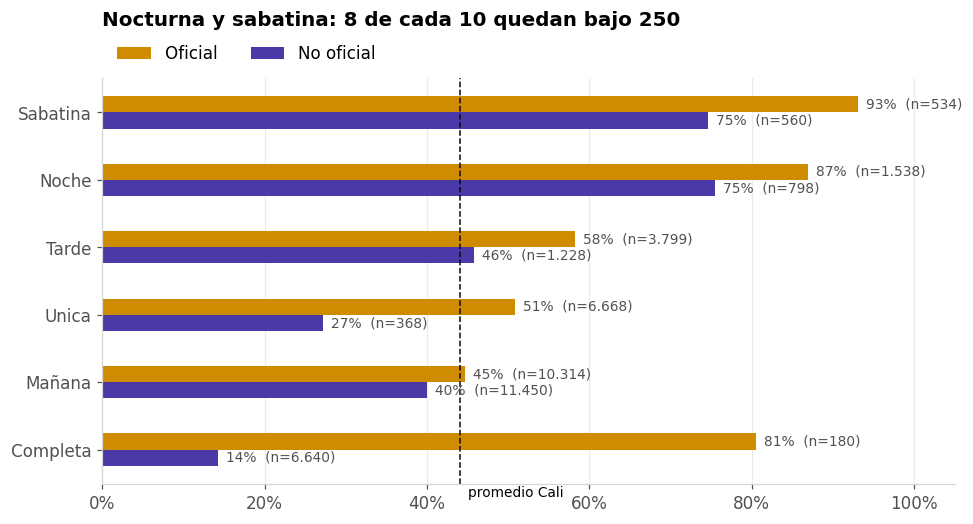

In [20]:
jor = df.groupby(["cole_jornada", "cole_naturaleza"])["bajo"].agg(tasa="mean", n="size").reset_index()
jor = jor[jor.n >= 30]
orden_j = df.groupby("cole_jornada")["bajo"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.8))
for nat_, col, dy in [("OFICIAL", ORANGE, .12), ("NO OFICIAL", BLUE, -.12)]:
    s = jor[jor.cole_naturaleza == nat_].set_index("cole_jornada").reindex(orden_j)
    yy = np.arange(len(orden_j)) + dy
    ax.barh(yy, s.tasa, height=.24, color=col, label=nat_.capitalize())
    for yi, (t, n) in zip(yy, zip(s.tasa, s.n)):
        if pd.notna(t): ax.text(t + .01, yi, f"{t:.0%}  (n={int(n):,})".replace(",", "."), va="center", fontsize=9, color=INK2)
ax.set_yticks(np.arange(len(orden_j)), [j.capitalize() for j in orden_j]); ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.05)
ax.axvline(df.bajo.mean(), color=INK, ls="--", lw=1); ax.text(df.bajo.mean() + .01, -.7, "promedio Cali", fontsize=9)
ax.set_title("Nocturna y sabatina: 8 de cada 10 quedan bajo 250", pad=34); ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.grid(axis="y", visible=False)
save(fig, "f07_jornada")

### 6.3 Brecha de riesgo por factor (con vs. sin la condición)

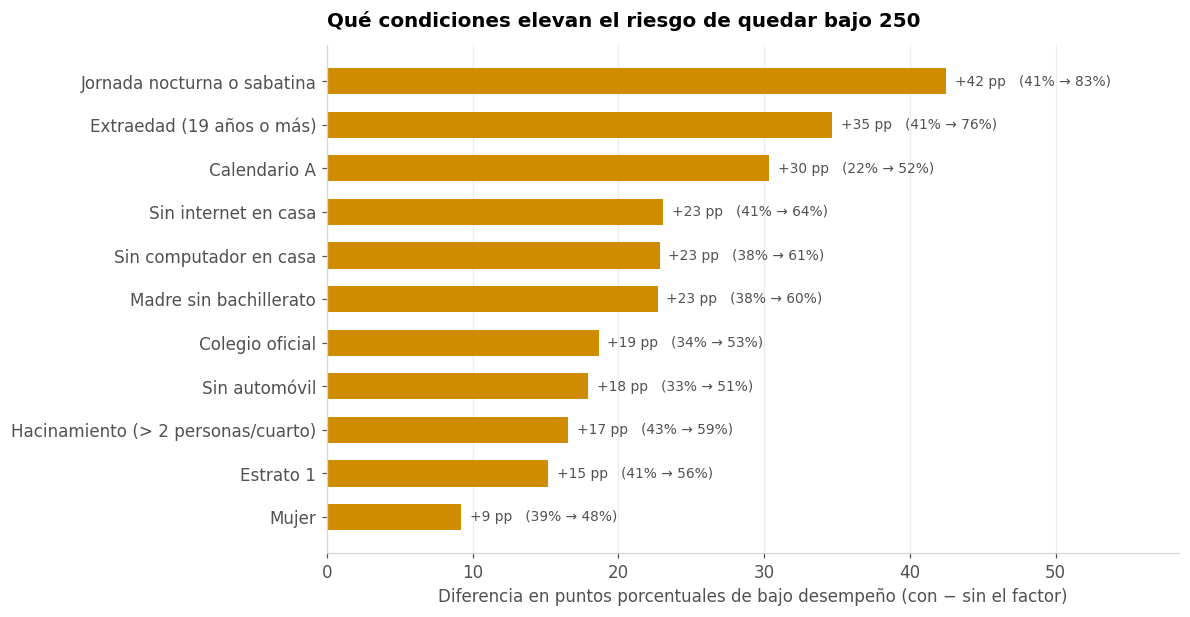

,factor,con,sin,n_con,brecha
7,Mujer,48.2%,38.9%,24164,9.2%
5,Estrato 1,56.3%,41.2%,8260,15.2%
6,Hacinamiento (> 2 personas/cuarto),59.1%,42.5%,3915,16.5%
10,Sin automóvil,50.9%,33.0%,27133,17.9%
8,Colegio oficial,52.9%,34.3%,23033,18.6%
2,Madre sin bachillerato,60.4%,37.7%,12182,22.7%
3,Sin computador en casa,60.7%,37.9%,11846,22.8%
4,Sin internet en casa,64.4%,41.3%,5209,23.1%
9,Calendario A,51.9%,21.5%,32612,30.4%
1,Extraedad (19 años o más),75.7%,41.1%,3678,34.6%


In [21]:
factores = {
    "Jornada nocturna o sabatina": df.cole_jornada.isin(["NOCHE", "SABATINA"]),
    "Extraedad (19 años o más)": df.extraedad == 1,
    "Madre sin bachillerato": df.edu_madre <= 3,
    "Sin computador en casa": df.fami_tienecomputador == "No",
    "Sin internet en casa": df.fami_tieneinternet == "No",
    "Estrato 1": df.estrato == 1,
    "Hacinamiento (> 2 personas/cuarto)": df.hacinamiento > 2,
    "Mujer": df.mujer == 1,
    "Colegio oficial": df.cole_naturaleza == "OFICIAL",
    "Calendario A": df.cole_calendario == "A",
    "Sin automóvil": df.fami_tieneautomovil == "No",
}
rows = []
for k, m in factores.items():
    m = m.fillna(False)
    rows.append({"factor": k, "con": df.loc[m, "bajo"].mean(), "sin": df.loc[~m, "bajo"].mean(), "n_con": int(m.sum())})
fac = pd.DataFrame(rows); fac["brecha"] = fac.con - fac.sin; fac = fac.sort_values("brecha")
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(fac))
ax.barh(yy, fac.brecha * 100, color=[ORANGE if b > 0 else BLUE for b in fac.brecha], height=.6)
for yi, (b, c, s) in zip(yy, zip(fac.brecha, fac.con, fac.sin)):
    ax.text(b * 100 + .6, yi, f"+{b*100:.0f} pp   ({s:.0%} → {c:.0%})", va="center", fontsize=9, color=INK2)
ax.set_yticks(yy, fac.factor); ax.set_xlabel("Diferencia en puntos porcentuales de bajo desempeño (con − sin el factor)")
ax.set_xlim(0, fac.brecha.max() * 100 + 16); ax.grid(axis="y", visible=False)
ax.set_title("Qué condiciones elevan el riesgo de quedar bajo 250")
save(fig, "f08_brecha_factores")
fac.assign(**{c: fac[c].map("{:.1%}".format) for c in ["con", "sin", "brecha"]})

### 6.4 El capital educativo del hogar: la educación de la madre

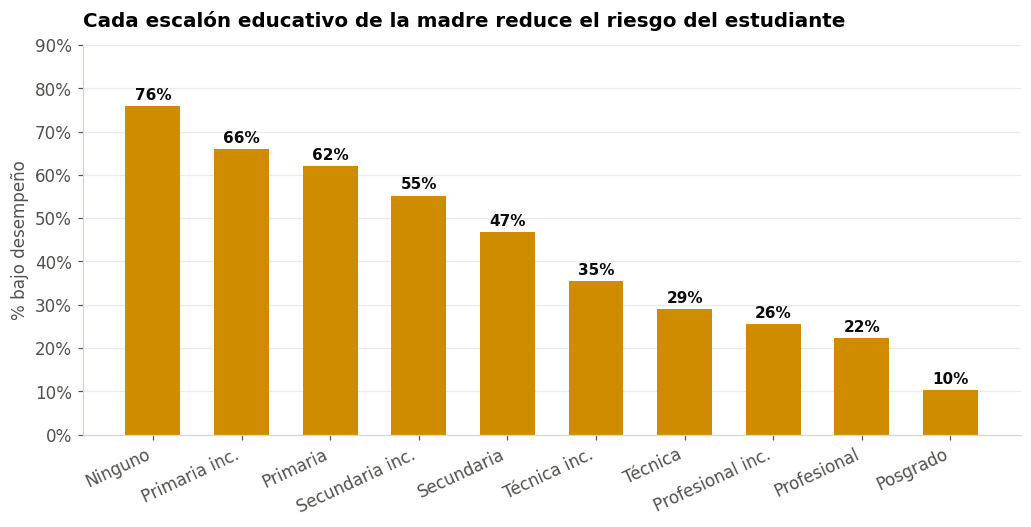

In [22]:
t = df.groupby("edu_madre")["bajo"].agg(tasa="mean", n="size").reindex(range(10))
fig, ax = plt.subplots(figsize=(11, 4.6))
cols = [SEQ[min(6, 6 - int(i * 0.7))] for i in range(10)]
ax.bar(range(10), t.tasa, color=ORANGE, width=.62)
for i, (v, n) in enumerate(zip(t.tasa, t.n)): ax.text(i, v + .015, f"{v:.0%}", ha="center", fontsize=10, fontweight="bold", color=INK)
ax.set_xticks(range(10), EDU_CORTA, rotation=25, ha="right"); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, .9)
ax.set_ylabel("% bajo desempeño"); ax.grid(axis="x", visible=False)
ax.set_title("Cada escalón educativo de la madre reduce el riesgo del estudiante")
save(fig, "f09_educacion_madre")

### 6.5 Interacción: estrato × educación de la madre

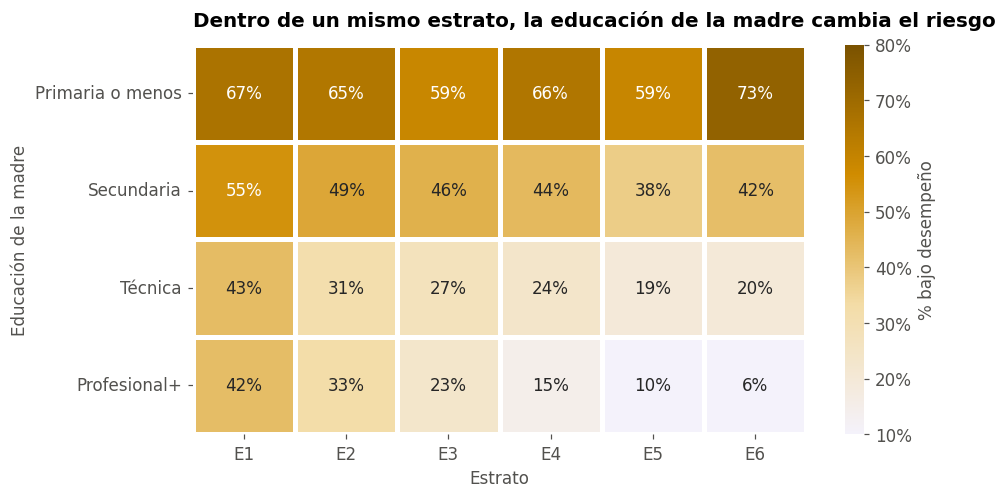

In [23]:
df["edu_madre_g"] = pd.cut(df.edu_madre, [-1, 2, 4, 6, 9], labels=["Primaria o menos", "Secundaria", "Técnica", "Profesional+"])
hm = df[df.estrato.between(1, 6)].pivot_table(index="edu_madre_g", columns="estrato", values="bajo", aggfunc="mean", observed=True)
hn = df[df.estrato.between(1, 6)].pivot_table(index="edu_madre_g", columns="estrato", values="bajo", aggfunc="size", observed=True)
hm = hm.where(hn >= 30)
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.heatmap(hm, annot=True, fmt=".0%", cmap=sns.blend_palette(["#f4f2fb", "#f3dca6", ORANGE, "#7a5200"], as_cmap=True),
            vmin=.1, vmax=.8, linewidths=2, linecolor="white", cbar_kws={"format": pct, "label": "% bajo desempeño"}, ax=ax)
ax.set_xlabel("Estrato"); ax.set_ylabel("Educación de la madre"); ax.set_xticklabels([f"E{int(c)}" for c in hm.columns], rotation=0)
ax.set_title("Dentro de un mismo estrato, la educación de la madre cambia el riesgo")
save(fig, "f10_interaccion_estrato_madre")

### 6.6 Brecha de género por área


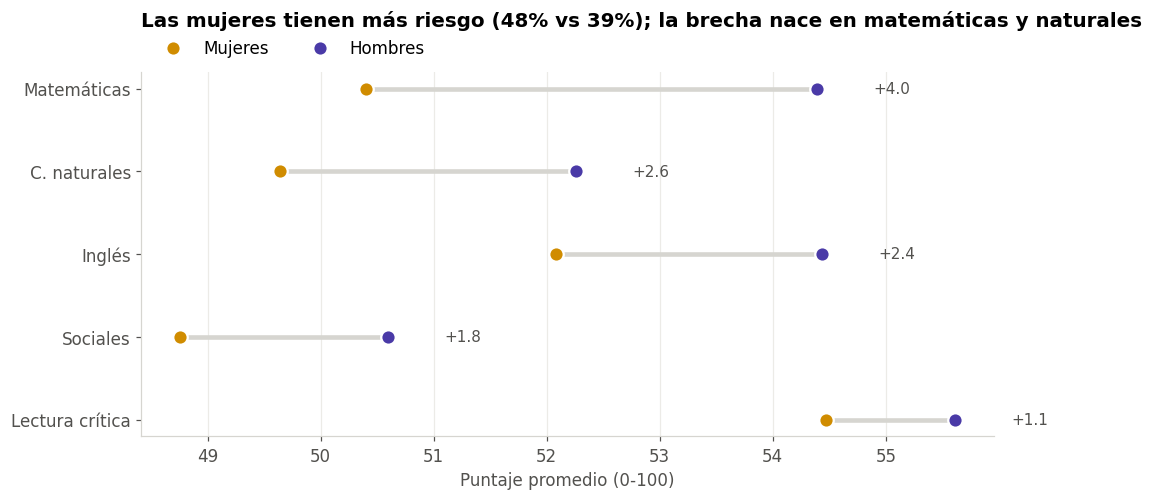

In [24]:
areas = {"punt_lectura_critica": "Lectura crítica", "punt_matematicas": "Matemáticas", "punt_sociales_ciudadanas": "Sociales",
         "punt_c_naturales": "C. naturales", "punt_ingles": "Inglés"}
g = df.groupby("estu_genero")[list(areas)].mean().T.rename(index=areas)
g["dif"] = g["M"] - g["F"]; g = g.sort_values("dif")
fig, ax = plt.subplots(figsize=(10, 4.3))
yy = np.arange(len(g))
ax.hlines(yy, g.F, g.M, color="#d6d5d0", lw=3)
ax.scatter(g.F, yy, s=90, color=ORANGE, label="Mujeres", zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter(g.M, yy, s=90, color=BLUE, label="Hombres", zorder=3, edgecolor="white", linewidth=1.5)
for yi, (f, m, d_) in enumerate(zip(g.F, g.M, g.dif)): ax.text(max(f, m) + .5, yi, f"{d_:+.1f}", va="center", fontsize=10, color=INK2)
ax.set_yticks(yy, g.index); ax.set_xlabel("Puntaje promedio (0-100)"); ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.grid(axis="y", visible=False)
ax.set_title(f"Las mujeres tienen más riesgo ({df[df.mujer==1].bajo.mean():.0%} vs {df[df.mujer==0].bajo.mean():.0%}); la brecha nace en matemáticas y naturales", pad=30)
save(fig, "f11_genero_areas")

### 6.7 Evolución del bajo desempeño por año


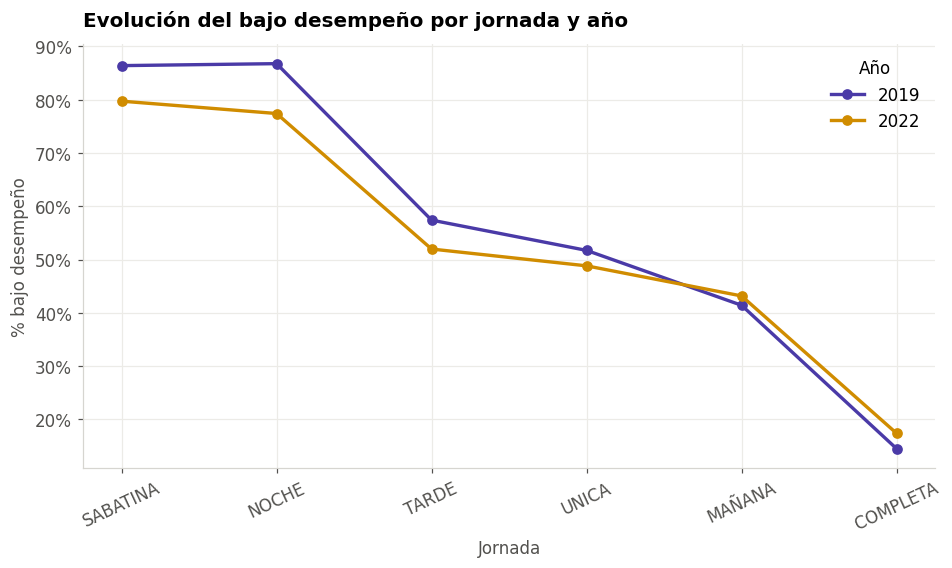

          n  tasa_bajo  media_global
anio                                
2019  21788      0.447       258.823
2022  22289      0.434       261.117


In [31]:
cmp_ = df.groupby(["cole_jornada", "anio"])["bajo"].mean().unstack()
cmp_ = cmp_.loc[cmp_.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 5))
for anio_, color in zip(cmp_.columns, [BLUE, ORANGE, AQUA, GRAY]):
    ax.plot(cmp_.index, cmp_[anio_], marker="o", lw=2.2, label=str(anio_), color=color)
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel("% bajo desempeño")
ax.set_xlabel("Jornada")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Año")
ax.set_title("Evolución del bajo desempeño por jornada y año")
save(fig, "f12_comparacion_anios")
print(df.groupby("anio").agg(n=("bajo", "size"), tasa_bajo=("bajo", "mean"), media_global=("punt_global", "mean")).round(3))

## 7. Correlación y redundancia

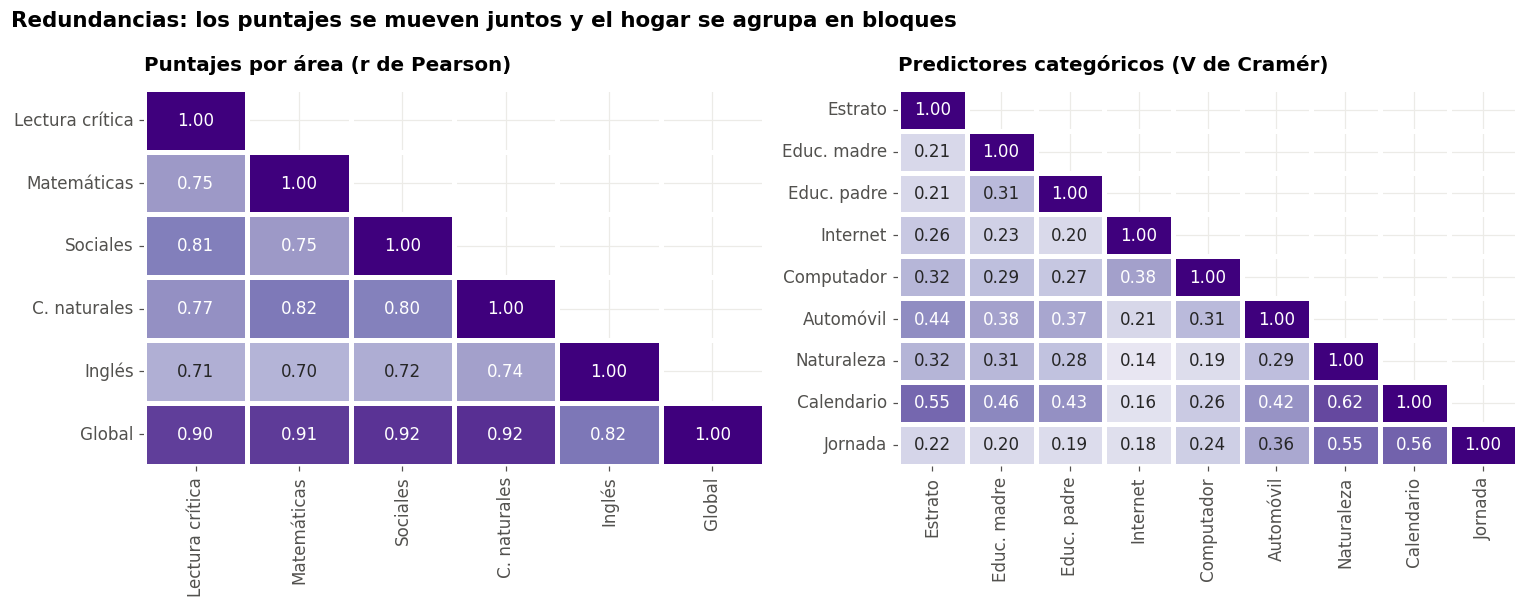

In [26]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6))
c = df[list(areas) + ["punt_global"]].rename(columns={**areas, "punt_global": "Global"}).corr()
mask = np.triu(np.ones_like(c, dtype=bool), 1)
sns.heatmap(c, mask=mask, annot=True, fmt=".2f", cmap="Purples", vmin=.5, vmax=1, linewidths=2, linecolor="white", cbar=False, ax=a1)
a1.set_title("Puntajes por área (r de Pearson)")

def cramers_v(x, y):
    ok = x.notna() & y.notna() & (x.astype(str) != "nan")
    t = pd.crosstab(x[ok], y[ok]); chi2 = chi2_contingency(t)[0]; n = t.values.sum(); r, k = t.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

pred_cat = {"fami_estratovivienda": "Estrato", "fami_educacionmadre": "Educ. madre", "fami_educacionpadre": "Educ. padre",
            "fami_tieneinternet": "Internet", "fami_tienecomputador": "Computador", "fami_tieneautomovil": "Automóvil",
            "cole_naturaleza": "Naturaleza", "cole_calendario": "Calendario", "cole_jornada": "Jornada"}
X = df[list(pred_cat)]
V = pd.DataFrame([[cramers_v(X[a], X[b]) for b in pred_cat] for a in pred_cat], index=pred_cat.values(), columns=pred_cat.values())
sns.heatmap(V, mask=np.triu(np.ones_like(V, dtype=bool), 1), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=.8,
            linewidths=2, linecolor="white", cbar=False, ax=a2)
a2.set_title("Predictores categóricos (V de Cramér)")
fig.suptitle("Redundancias: los puntajes se mueven juntos y el hogar se agrupa en bloques", x=.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "f13_redundancias")

### 7.1 Fuerza de asociación de cada predictor con el bajo desempeño

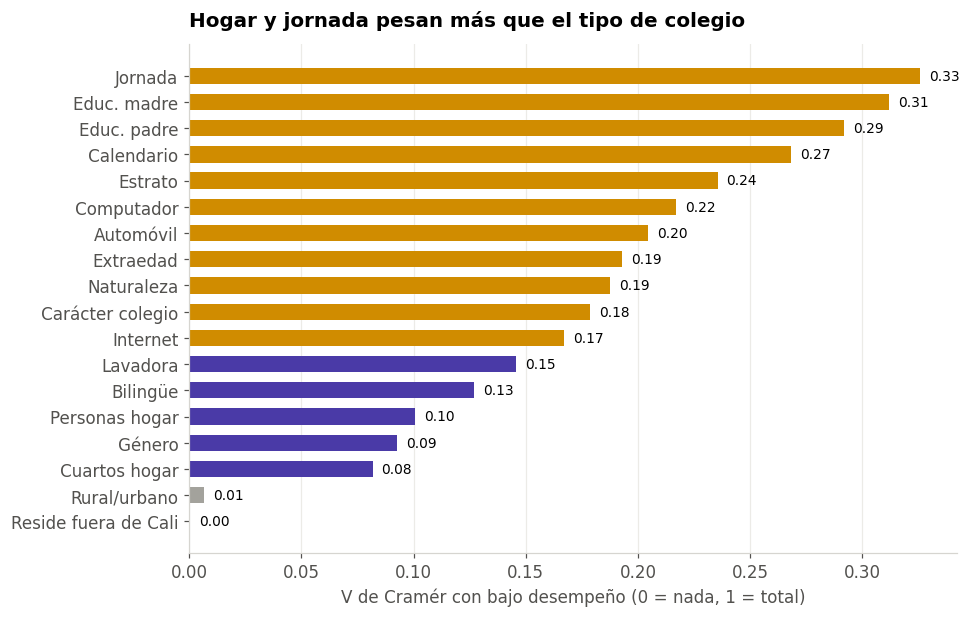

Jornada                 0.326
Educ. madre             0.312
Educ. padre             0.292
Calendario              0.268
Estrato                 0.235
Computador              0.217
Automóvil               0.204
Extraedad               0.193
Naturaleza              0.187
Carácter colegio        0.179
Internet                0.167
Lavadora                0.146
Bilingüe                0.127
Personas hogar          0.101
Género                  0.092
Cuartos hogar           0.082
Rural/urbano            0.007
Reside fuera de Cali    0.000
dtype: float64

In [27]:
todos = {**pred_cat, "cole_bilingue": "Bilingüe", "cole_area_ubicacion": "Rural/urbano", "estu_genero": "Género",
         "fami_tienelavadora": "Lavadora", "fami_personashogar": "Personas hogar", "fami_cuartoshogar": "Cuartos hogar",
         "cole_caracter": "Carácter colegio", "extraedad": "Extraedad", "reside_fuera_cali": "Reside fuera de Cali"}
asoc = pd.Series({v: cramers_v(df[k].astype(str), df["bajo"]) for k, v in todos.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(asoc.index, asoc.values, color=[ORANGE if v >= .15 else BLUE if v >= .08 else GRAY for v in asoc.values], height=.62)
for i, v in enumerate(asoc.values): ax.text(v + .004, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("V de Cramér con bajo desempeño (0 = nada, 1 = total)"); ax.grid(axis="y", visible=False)
ax.set_title("Hogar y jornada pesan más que el tipo de colegio")
save(fig, "f14_asociacion_objetivo")
asoc.sort_values(ascending=False).round(3)

## 8. Conclusiones del EDA
Se resumen las cifras principales usando **todos los años que realmente estén presentes en el archivo cargado**.


In [28]:
resumen = {
    "Filas publicadas": len(raw),
    "Duplicados exactos": int(raw.duplicated().sum()),
    "Registros válidos": len(df),
    "Años disponibles": ", ".join(sorted(df["anio"].unique())),
    "Colegios": df.cole_cod_dane_establecimiento.nunique(),
    "Tasa bajo desempeño general": round(df.bajo.mean(), 3),
    "Media puntaje global": round(df.punt_global.mean(), 1),
}
pd.Series(resumen)


Filas publicadas                    80350
Duplicados exactos                  36221
Registros válidos                   44077
Años disponibles               2019, 2022
Colegios                              404
Tasa bajo desempeño general          0.44
Media puntaje global                260.0
dtype: object